# 系统改进与工程实验
## Goal
把概念变成可检查的输入、运算、梯度与对照。

数据类型：**真实快照 + 受控漂移/社交模拟**。本地教学参数不是生产默认值；机制实验不是原论文完整复现。

## Setup
每本首次从 Setup 起顺序运行，后面的格会复用前面的变量。之后只改一个参数，重跑对应格及下游格。不要把构造数据当作真实业务收益。

In [1]:
from pathlib import Path
import sys
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "reclab/models.py").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from reclab.data import Dataset
from reclab.paths import ARTIFACTS, PROCESSED, read_json

plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#182b2b", "text.color": "#182b2b",
    "axes.facecolor": "white", "figure.facecolor": "white",
    "grid.color": "#d4ddda", "axes.axisbelow": True})
dataset = Dataset()
print("Project:", PROJECT)
print("Dataset version:", dataset.manifest["dataset_version"])
print("Python:", sys.executable)
assert Path(sys.executable).parent == PROJECT / ".venv/bin", "请选择 Recommendation Lab 内核"

Project: /Users/lizuolin/local/recommendation-lab
Dataset version: 2772cab0aca8cb81
Python: /Users/lizuolin/local/recommendation-lab/.venv/bin/python


## Steps
讲义对应：08_Improvement_01.pdf, 08_Improvement_02.pdf, 08_Improvement_03.pdf, 08_Improvement_04.pdf, 08_Improvement_05.pdf, 08_Improvement_06.pdf

### 召回配额与去重
真实训练快照中的热门、ItemCF 和双塔候选；候选数相加不等于去重后的数量。

**先预测：** 固定总预算，调整配额时应同时观察哪些质量、覆盖与时延指标？

In [2]:
from scipy import sparse
from reclab.retrieval import cf_scores,topk
from reclab.train import load_model,model_scorer
user=next(iter(dataset.histories));sim=sparse.load_npz(ARTIFACTS/"baselines/itemcf.npz")
model,report=load_model(dataset,"baseline-history32");scorer,_=model_scorer(dataset,model)
channels={"popular":topk(dataset.popularity,100,dataset.seen[user]),
    "itemcf":topk(cf_scores(sim,dataset.histories[user],dataset.n_items),100,dataset.seen[user]),
    "tower":topk(scorer(user),100,dataset.seen[user])}
display(pd.DataFrame([{"per_channel":n,"sum_before":3*n,
    "unique_after":len(set().union(*(set(ids[:n]) for ids in channels.values())))} for n in [10,30,100]]))

,per_channel,sum_before,unique_after
0,10,30,30
1,30,90,90
2,100,300,295


### 粗精排蒸馏
受控 teacher/student 分数；检查 KL 的方向和梯度，不宣称已有完整精排模型。

**先预测：** teacher 很差时，更好地拟合 teacher 是否一定更好？

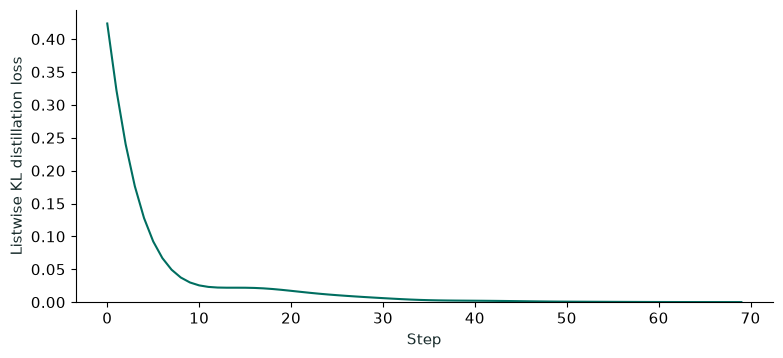

In [3]:
import torch
from reclab.learning.systems import distillation_loss
torch.manual_seed(42);torch.set_num_threads(4)
teacher=torch.randn(8,20);student=torch.nn.Parameter(torch.zeros(8,20))
opt=torch.optim.Adam([student],lr=.15);curve=[]
for _ in range(70):
    opt.zero_grad();loss=distillation_loss(student,teacher,2.)
    loss.backward();opt.step();curve.append(float(loss.detach()))
assert curve[-1]<curve[0]
plt.plot(curve,color="#006e60");plt.xlabel("Step");plt.ylabel("Listwise KL distillation loss");plt.ylim(bottom=0);plt.show()

### 全量、增量与分布漂移
受控二分类规律改变，展示继续训练与从头训练。训练准确率不等于泛化或线上老汤模型收益。

**先预测：** 旧数据继续保留多少，才能兼顾遗忘与新分布适应？

In [4]:
torch.manual_seed(42)
x=torch.randn(512,4);old_y=(x[:,0]+x[:,1]>0).float();new_y=(-x[:,0]+x[:,1]>0).float()
def fit(net,label,steps):
    optimizer=torch.optim.SGD(net.parameters(),lr=.2)
    for _ in range(steps):
        optimizer.zero_grad();loss=torch.nn.functional.binary_cross_entropy_with_logits(net(x).squeeze(-1),label)
        loss.backward();optimizer.step()
    return net
old=fit(torch.nn.Linear(4,1),old_y,80)
import copy
incremental=fit(copy.deepcopy(old),new_y,20);fresh=fit(torch.nn.Linear(4,1),new_y,20)
display(pd.DataFrame([{"model":name,"new_distribution_training_accuracy":float(((net(x).squeeze(-1)>0)==new_y.bool()).float().mean())}
    for name,net in [("old",old),("incremental20",incremental),("fresh20",fresh)]]))

,model,new_distribution_training_accuracy
0,old,0.533203
1,incremental20,0.710938
2,fresh20,0.919922


### 特殊人群、多样性、探索与社交
按训练期活跃度分层；关注/作者/站外回流缺失，社交关系明确使用构造字典。探索比例不能由静态日志验证长期收益。

**先预测：** 为什么不能用未来一周的活跃度给今天的用户分组？

In [5]:
activity=pd.Series({u:len(h) for u,h in dataset.histories.items()})
groups=pd.cut(activity,bins=[0,10,50,np.inf],labels=["low","medium","high"])
display(groups.value_counts(sort=False).to_frame("training-defined users"))
synthetic_follows={"u1":{"authorA","authorB"}}
synthetic_items={"authorA":["i1","i2"],"authorB":["i3"]}
social={i for author in synthetic_follows["u1"] for i in synthetic_items[author]}
assert social=={"i1","i2","i3"}
print("Synthetic U2A2I:",sorted(social))
print("MMR/diversity experiments: chapter 08. Exploration 2% is a hypothesis, not a universal default.")

,training-defined users
low,3843
medium,2643
high,248


Synthetic U2A2I: ['i1', 'i2', 'i3']
MMR/diversity experiments: chapter 08. Exploration 2% is a hypothesis, not a universal default.


## Checks
所有断言和输出都可回溯到代码。它们验证算子、数据快照或机制，不是线上收益。

## Next Steps
先记录预测，只改一个变量，再运行对应实验格。需要查看辅助函数时，打开 reclab/learning/。